In [6]:
essay = """# Generation Z (Gen Z)

## Introduction

Generation Z, commonly known as **Gen Z**, is the generation that comes after Millennials and before Generation Alpha. Although the exact years vary depending on the source, Gen Z is generally considered to include people born from the late 1990s to the early 2010s. This generation has grown up during a period of rapid technological, social, and cultural change.

Gen Z is often called the **first truly digital generation** because the internet, smartphones, social media, and digital technology have been a normal part of their lives from an early age. Unlike previous generations that had to adapt to the digital world, Gen Z was born into a world where information, entertainment, communication, and education are increasingly available online.

## Technology and Gen Z

Technology has had a major influence on Gen Z. Smartphones, social media platforms, video-sharing websites, online games, artificial intelligence, and other digital tools are deeply connected to their everyday lives.

For many Gen Z individuals, communicating with friends does not necessarily require meeting face-to-face. They can send messages, make video calls, share photos, or interact through social media within seconds. Similarly, learning is no longer limited to classrooms and textbooks. A student can watch educational videos, take online courses, use AI tools, read digital books, and search for information from almost anywhere.

This close relationship with technology has made Gen Z comfortable with learning and using new digital tools. At the same time, excessive dependence on technology can create problems such as distraction, reduced attention spans, privacy concerns, and excessive screen time.

## Social Media

Social media is one of the most important parts of Gen Z culture. Platforms such as Instagram, TikTok, YouTube, Snapchat, and others have changed the way young people communicate and consume information.

Social media allows Gen Z to express their opinions, share their creativity, follow trends, build communities, and even create businesses. A young person with a smartphone can become a content creator, educator, entertainer, or entrepreneur without needing traditional media companies.

However, social media also has negative effects. Constant exposure to carefully edited images and lifestyles can create unrealistic expectations. Some young people may compare their lives with influencers and celebrities, leading to dissatisfaction with themselves or their lifestyles. Social media can also spread misinformation very quickly.

Therefore, one of the most important skills for Gen Z is learning how to use social media responsibly and critically.

## Education

Gen Z has experienced significant changes in education. Traditional education is increasingly being combined with digital learning. Students can access lectures, tutorials, research papers, courses, and educational communities online.

The rise of artificial intelligence has created another major change. AI tools can help students understand difficult concepts, practice skills, generate ideas, and receive explanations. However, students must learn to use these tools as assistants rather than simply depending on them to complete their work.

Gen Z's relationship with education also reflects a growing desire for practical knowledge. Many young people are interested in skills such as programming, digital marketing, graphic design, content creation, entrepreneurship, artificial intelligence, and freelancing.

## Work and Career

Gen Z is entering the workforce at a time when the traditional idea of a career is changing. Remote work, freelancing, startups, the creator economy, and digital businesses have created opportunities that were not as common for previous generations.

Many Gen Z workers value flexibility, personal growth, meaningful work, and a healthy balance between professional and personal life. They may be less interested in staying with one organization for their entire career and more willing to change jobs or careers when they find better opportunities.

Technology is also changing the types of jobs available. Artificial intelligence and automation are transforming many industries. As a result, Gen Z will need to continuously develop new skills and adapt to technological changes.

## Creativity and Entrepreneurship

One of Gen Z's notable characteristics is its strong connection with digital creativity. A smartphone can now function as a camera, editing studio, publishing platform, and business tool.

Young people can create videos, podcasts, digital products, applications, online stores, and personal brands with relatively small investments. Platforms such as YouTube and TikTok have also made it possible for individuals to reach large audiences without traditional media organizations.

This has encouraged many Gen Z individuals to think beyond traditional employment. Instead of asking only, "Which company should I work for?" some are asking, "What can I build myself?"

## Challenges Faced by Gen Z

Despite having access to more technology and information than previous generations, Gen Z faces several challenges.

One major challenge is **information overload**. Young people can encounter thousands of pieces of information every day, making it difficult to determine what is accurate and what is misleading.

Another challenge is maintaining a healthy relationship with technology. Smartphones and social media can make it difficult to disconnect from the digital world.

Gen Z also faces uncertainty about the future of employment because automation and artificial intelligence are changing traditional jobs. Developing adaptable skills will therefore be increasingly important.

Additionally, economic pressures, competition, academic expectations, and social pressure can make the transition into adulthood difficult.

## Gen Z and Communication

Communication has changed significantly because of digital technology. Gen Z commonly uses short messages, emojis, memes, GIFs, voice messages, and short-form videos to communicate ideas and emotions.

Memes in particular have become an important part of online culture. A single image or short video can communicate an idea that would require an entire paragraph to explain.

However, digital communication can sometimes reduce face-to-face interaction. Developing strong communication skills in both digital and real-world environments remains important.

## Gen Z and Society

Gen Z is growing up in a highly connected world. Events happening in one country can become known globally within minutes. This has created a generation that is exposed to different cultures, ideas, lifestyles, and perspectives.

Because of this global connectivity, Gen Z has the potential to influence society in significant ways. Their choices as consumers, workers, voters, creators, and entrepreneurs will help shape the future.

At the same time, their ability to influence society comes with responsibility. Being digitally connected means that people need to think carefully about what they share, believe, and promote online.

## Conclusion

Generation Z is a unique generation shaped by technology, social media, globalization, and rapid change. Its members have grown up with smartphones, the internet, and digital communication as ordinary parts of life.

Gen Z has many strengths, including technological adaptability, creativity, entrepreneurial thinking, and access to enormous amounts of information. However, it also faces challenges such as digital distraction, social pressure, misinformation, economic uncertainty, and the changing nature of employment.

Ultimately, Gen Z's greatest advantage may be its ability to adapt. The world is changing quickly, and the generation that has grown up with constant technological change may be well prepared to navigate that future.

The future will not simply be shaped by Gen Z's use of technology. It will be shaped by **how wisely they use it**—to learn, create, communicate, solve problems, and build something better for the generations that follow.
"""

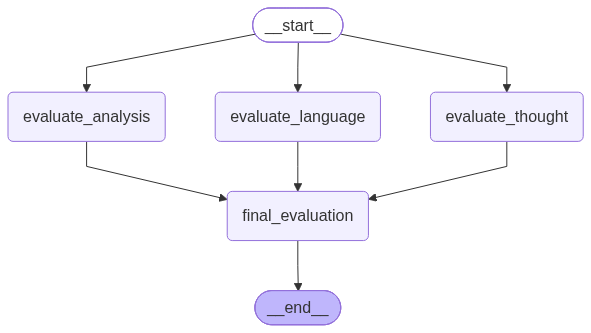

In [34]:
work_flow

In [55]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict, Annotated
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator

load_dotenv()


model = ChatGroq(
    model="openai/gpt-oss-20b"
)


class Evaluation(BaseModel):
    feedback: str = Field(
        description="Detailed feedback on essay"
    )
    
    score: int = Field(
        description="Score out of 10",
        ge=0,
        le=10
    )


structured_output = model.with_structured_output(Evaluation)


class CSSSTATE(TypedDict):
    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int], operator.add]
    avg_score: float


def evaluate_language(state: CSSSTATE):
    prompt = f'''
    Evaluate the language quality of the essay and rate it between 1 and 10.

    Essay:
    {state["essay"]}
    '''

    output = structured_output.invoke(prompt)

    return {
        'language_feedback': output.feedback,
        'individual_scores': [output.score]
    }


def evaluate_analysis(state: CSSSTATE):
    prompt = f'''
    Evaluate the depth and quality of analysis in the essay and rate it between 1 and 10.

    Essay:
    {state["essay"]}
    '''

    output = structured_output.invoke(prompt)

    return {
        'analysis_feedback': output.feedback,
        'individual_scores': [output.score]
    }


def evaluate_thought(state: CSSSTATE):
    prompt = f'''
    Evaluate the clarity of thought in the essay and rate it between 1 and 10.

    Essay:
    {state["essay"]}
    '''

    output = structured_output.invoke(prompt)

    return {
        'clarity_feedback': output.feedback,
        'individual_scores': [output.score]
    }


def final_evaluation(state: CSSSTATE):
    prompt = f'''
    Based on the following feedbacks, create a summarized feedback.

    Language feedback:
    {state["language_feedback"]}

    Depth of analysis feedback:
    {state["analysis_feedback"]}

    Clarity of thought feedback:
    {state["clarity_feedback"]}
    '''

    overall_feedback = model.invoke(prompt).content

    avg_score = sum(state['individual_scores']) / len(state['individual_scores'])

    return {
        'overall_feedback': overall_feedback,
        'avg_score': avg_score
    }


graph = StateGraph(CSSSTATE)

graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('final_evaluation', final_evaluation)


graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge(START, 'evaluate_thought')

graph.add_edge('evaluate_language', 'final_evaluation')
graph.add_edge('evaluate_analysis', 'final_evaluation')
graph.add_edge('evaluate_thought', 'final_evaluation')

graph.add_edge('final_evaluation', END)


work_flow = graph.compile()


initial_state = {
    'essay': essay
}

result = work_flow.invoke(initial_state)

print("LANGUAGE FEEDBACK:")
print(result['language_feedback'])

print("\nANALYSIS FEEDBACK:")
print(result['analysis_feedback'])

print("\nCLARITY OF THOUGHT:")
print(result['clarity_feedback'])

print("\nOVERALL FEEDBACK:")
print(result['overall_feedback'])

print("\nAVERAGE SCORE:")
print(result['avg_score'])

LANGUAGE FEEDBACK:
The essay demonstrates solid overall language proficiency with clear organization and appropriate vocabulary for a general audience. The use of headings and subheadings improves readability and signals transitions. Sentence structures are mostly varied, though there are occasional instances of run‑on sentences and slightly repetitive phrasing (e.g., repeated use of "digital" and “technology”). Punctuation is generally correct, but some commas are missing before subordinate clauses, and a few sentences could be split for clarity. Word choice is suitable, yet there are moments of informal diction that could be refined for academic tone (e.g., “a student can watch educational videos” could be more formally expressed). The essay occasionally lacks depth in analysis; some claims are stated as facts without supporting evidence or examples. Additionally, the conclusion repeats earlier points rather than synthesizing them into a new insight. Overall, the language quality is 